# 02 · Curation and labelling

Turns the raw activity rows notebook 01 profiled into one labelled table per pathogen. Every
decision is a key in `CONFIG`, so changing one and rerunning is a sensitivity analysis rather than
an edit.

**The six decisions**, settled in `notebooks/README.md` and applied here:

| decision | the answer |
|---|---|
| activity threshold | 32 µM primary, 10 µM reported as a sensitivity check |
| censored rows | kept. `>`/`>=` at or above the threshold are negatives, `<`/`<=` at or below are positives, a `>` below the threshold says nothing and the compound drops out |
| units | converted through RDKit molecular weight; unconvertible rows are dropped and counted |
| repeats | one label per compound, active wins over inactive across papers |
| organisms | apart. Three tables, three models later, no organism feature |
| plant-derived compounds | flagged here, held out in 03, never trained on |

Deduplication is by **InChIKey skeleton** (the first block, connectivity only), so salt forms and
stereoisomers cannot straddle a split later.

**Output.** `data/processed/02_labelled_<organism>.parquet`, one per pathogen, read by
`03_features.ipynb`. Figures are written to `figures/`, prefixed `02_`.

Code: `pipeline/curation.py`, `pipeline/labels.py`, `pipeline/features.py`.

## 0. Settings

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from pipeline import curation, data, labels, viz

viz.use_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 120)

CONFIG = {
    "pathogens": curation.PATHOGENS,
    "standard_type": os.environ.get("ETHNOHACK_STANDARD_TYPE", "mic"),
    "threshold_um": float(os.environ.get("ETHNOHACK_THRESHOLD_UM", curation.PRIMARY_THRESHOLD_UM)),
    "sensitivity_threshold_um": float(
        os.environ.get("ETHNOHACK_SENSITIVITY_UM", curation.SENSITIVITY_THRESHOLD_UM)
    ),
    "drop_chembl_flagged": True,
    "dedup_key": "inchikey_skeleton",
    "repeat_rule": "active wins over inactive",
}
pd.Series(CONFIG, name="value").to_frame()

,value
pathogens,"[Staphylococcus aureus, Escherichia coli, Myco..."
standard_type,mic
threshold_um,32.0
sensitivity_threshold_um,10.0
drop_chembl_flagged,True
dedup_key,inchikey_skeleton
repeat_rule,active wins over inactive


## 1. Curating each pathogen

One pass per pathogen. The step table is the audit trail: every row that leaves the dataset leaves
at a named step, and the count after each step is shown rather than described.

In [2]:
tables, step_reports, cleaned = {}, {}, {}
for organism in CONFIG["pathogens"]:
    table, steps, rows = curation.curate(
        organism,
        threshold_um=CONFIG["threshold_um"],
        standard_type=CONFIG["standard_type"],
        drop_flagged=CONFIG["drop_chembl_flagged"],
    )
    tables[organism] = table
    step_reports[organism] = steps
    cleaned[organism] = rows
    print(f"{organism}: {len(table):,} labelled compounds from {len(rows):,} usable rows")

Staphylococcus aureus: 58,335 labelled compounds from 154,933 usable rows


Escherichia coli: 43,280 labelled compounds from 85,552 usable rows


Mycobacterium tuberculosis: 23,138 labelled compounds from 45,824 usable rows


,S. aureus,E. coli,M. tuberculosis
step,,,
raw MIC rows,160956,90099,47619
drop rows ChEMBL flagged as suspect,160140,89567,47538
drop rows with no structure,159349,88678,47463
drop rows with no usable numeric value,155782,86338,45828
drop rows whose structure does not parse,155781,86337,45828
drop rows whose units cannot be converted,154933,85552,45824
distinct structures in those rows,61574,46025,24552
distinct compounds after InChIKey-skeleton dedup,59596,44490,24025
compounds with a verdict at 32 uM,58335,43280,23138


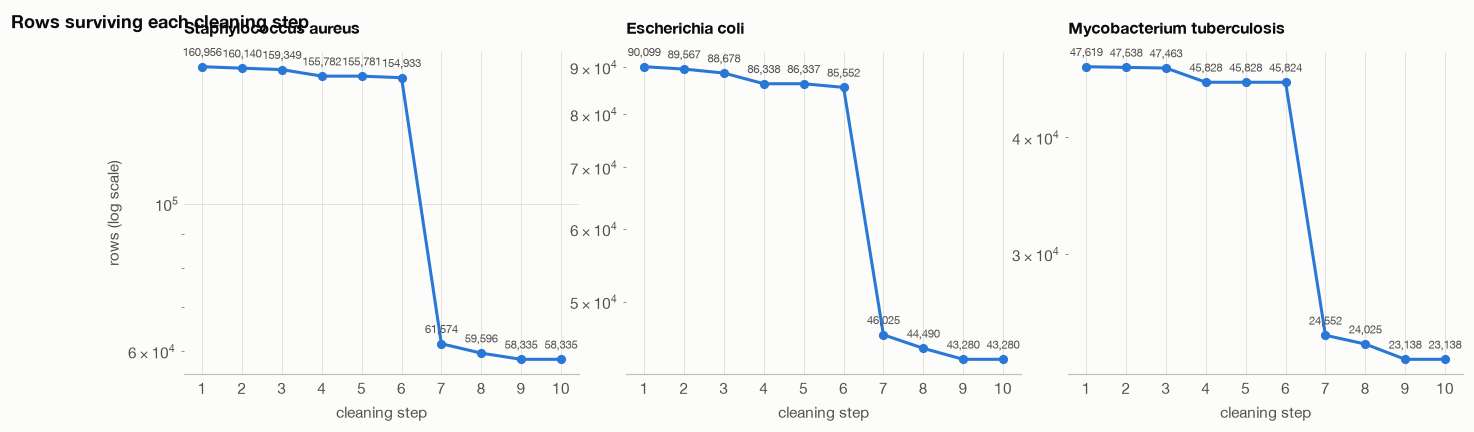

In [3]:
merged = None
for organism, steps in step_reports.items():
    column = steps.set_index("step").rows.rename(organism.split()[0][0] + ". " + organism.split()[1])
    merged = column.to_frame() if merged is None else merged.join(column, how="outer")
merged = merged.loc[step_reports[CONFIG["pathogens"][0]].step]
display(merged)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw=dict(wspace=0.12))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    steps = step_reports[organism]
    counts = steps.rows.to_numpy()
    ax.plot(range(len(counts)), counts, marker="o", markersize=5, color=viz.SERIES[0])
    ax.set_yscale("log")
    ax.set_xticks(range(len(counts)), [str(i + 1) for i in range(len(counts))])
    ax.set_xlabel("cleaning step")
    ax.set_title(organism, fontsize=10.5)
    for i, v in enumerate(counts):
        ax.annotate(f"{v:,}", (i, v), textcoords="offset points", xytext=(0, 7),
                    ha="center", fontsize=7.5, color=viz.INK_SECONDARY)
axes[0].set_ylabel("rows (log scale)")
fig.suptitle("Rows surviving each cleaning step", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "02_cleaning_steps")
plt.show()

The drop between step 6 and step 7 is not a loss. That is where many measurements of one compound
become one compound: the rows above it are measurements, the rows below it are structures. Step 8
is the skeleton deduplication, which merges salt forms and stereoisomers and costs a further 1,978,
1,535 and 527 compounds. Step 9 is the labelling, which drops compounds whose measurements give no
verdict at this threshold.

## 2. What the unit conversion costs

Notebook 01 found 37 distinct unit strings. Most are mass per volume, which needs a molecular
weight to become a concentration, so a structure that does not parse takes its measurement with it.

In [4]:
unit_report = []
for organism in CONFIG["pathogens"]:
    raw = curation.load_activity(organism, CONFIG["standard_type"])
    kept = cleaned[organism]
    units = raw.standard_units.fillna("(none)").value_counts()
    unit_report.append({
        "pathogen": organism,
        "distinct unit strings": raw.standard_units.nunique(),
        "most common unit": units.index[0],
        "rows in that unit": int(units.iloc[0]),
        "rows kept after conversion": len(kept),
        "share of raw rows kept": f"{len(kept) / len(raw):.1%}",
    })
pd.DataFrame(unit_report).set_index("pathogen")

,distinct unit strings,most common unit,rows in that unit,rows kept after conversion,share of raw rows kept
pathogen,,,,,
Staphylococcus aureus,28,ug.mL-1,137160,154933,96.3%
Escherichia coli,26,ug.mL-1,74829,85552,95.0%
Mycobacterium tuberculosis,6,ug.mL-1,23519,45824,96.2%


## 3. Class balance, at both thresholds

The primary threshold is 32 µM. The 10 µM column is the sensitivity check: a stricter definition of
active, which moves compounds from the positive class to the negative one and tells us whether the
balance is an artefact of where the line was drawn.

One result below looks backwards and is not. The **compound count goes up** at the stricter
threshold rather than down. A compound whose only measurement is `>16 µM` says nothing at 32 µM and
is dropped for want of a verdict; at 10 µM the same measurement is informative, because failing
above 16 means failing at 10, so the compound enters as a negative. Lowering the threshold rescues
compounds as well as reclassifying them.

,compounds @32uM,active @32uM,active rate @32uM,compounds @10uM,active @10uM,active rate @10uM
pathogen,,,,,,
Staphylococcus aureus,58335,31890,54.7%,59309,23995,40.5%
Escherichia coli,43280,17099,39.5%,44250,11670,26.4%
Mycobacterium tuberculosis,23138,13533,58.5%,23711,9293,39.2%


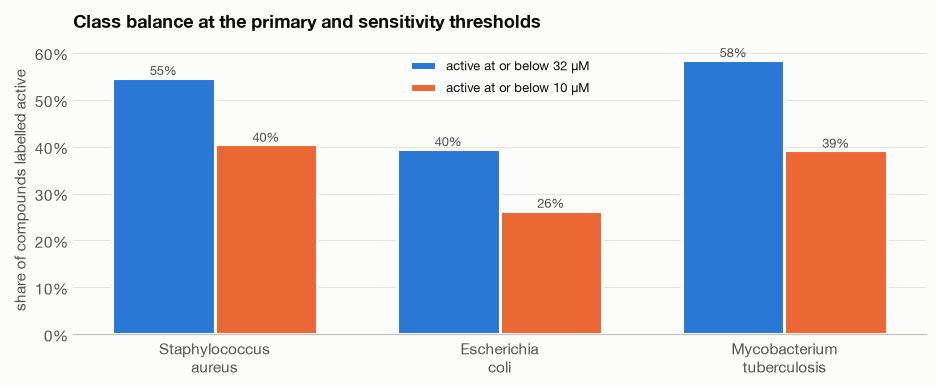

In [5]:
balance = []
alt_labels = {}
for organism in CONFIG["pathogens"]:
    rows = cleaned[organism]
    primary = tables[organism].label
    alt = labels.label_table(
        rows, "skeleton", "standard_relation", "value_um", CONFIG["sensitivity_threshold_um"]
    )
    alt_labels[organism] = alt
    alt_series = pd.Series(alt)
    balance.append({
        "pathogen": organism,
        f"compounds @{CONFIG['threshold_um']:g}uM": len(primary),
        f"active @{CONFIG['threshold_um']:g}uM": int(primary.sum()),
        f"active rate @{CONFIG['threshold_um']:g}uM": primary.mean(),
        f"compounds @{CONFIG['sensitivity_threshold_um']:g}uM": len(alt_series),
        f"active @{CONFIG['sensitivity_threshold_um']:g}uM": int(alt_series.sum()),
        f"active rate @{CONFIG['sensitivity_threshold_um']:g}uM": alt_series.mean(),
    })
balance = pd.DataFrame(balance).set_index("pathogen")
display(balance.style.format({c: "{:.1%}" for c in balance.columns if "rate" in c}))

fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(CONFIG["pathogens"]))
width = 0.36
for i, th in enumerate([CONFIG["threshold_um"], CONFIG["sensitivity_threshold_um"]]):
    rates = balance[f"active rate @{th:g}uM"].to_numpy()
    ax.bar(x + (i - 0.5) * width, rates, width=width, color=viz.SERIES[i],
           edgecolor=viz.SURFACE, linewidth=2, label=f"active at or below {th:g} µM")
    for xi, v in zip(x + (i - 0.5) * width, rates):
        ax.text(xi, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8.5,
                color=viz.INK_SECONDARY)
ax.set_xticks(x, [o.replace(" ", "\n") for o in CONFIG["pathogens"]])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel("share of compounds labelled active")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8.5)
ax.set_title("Class balance at the primary and sensitivity thresholds")
viz.save(fig, "02_class_balance")
plt.show()

## 4. How much of the negative class is censored

A `>` measurement is a compound that was tested and did not work at the highest concentration
tried. Those rows are the negative class. If almost all negatives came from censored rows the
labels would be measuring reporting habits as much as chemistry, so this is worth knowing before
any model sees the data.

,negatives,negatives entirely from censored rows,share of negatives,positives with any censored row
pathogen,,,,
Staphylococcus aureus,26445,10177,38.5%,2239
Escherichia coli,26181,12118,46.3%,1631
Mycobacterium tuberculosis,9605,3567,37.1%,774


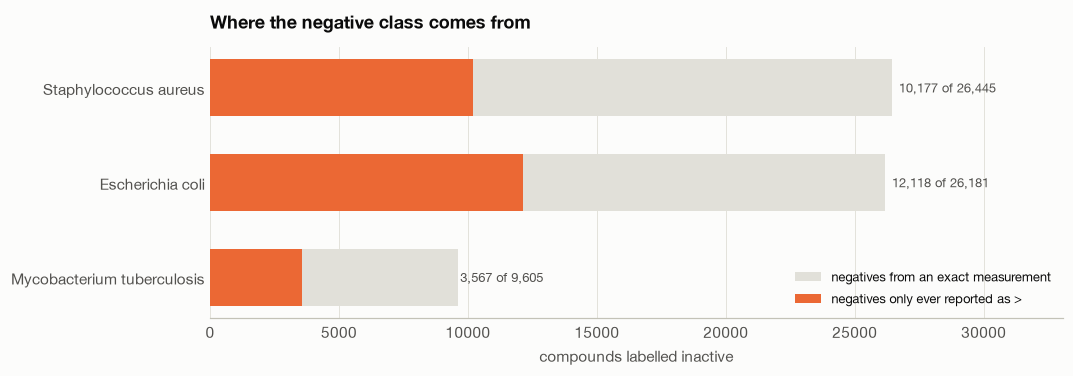

In [6]:
censored_report = []
for organism in CONFIG["pathogens"]:
    rows = cleaned[organism]
    table = tables[organism]
    flags = curation.censored_contribution(rows, CONFIG["threshold_um"])
    negatives = table[table.label.eq(0)].skeleton
    positives = table[table.label.eq(1)].skeleton
    neg_flags = flags.reindex(negatives).dropna()
    pos_flags = flags.reindex(positives).dropna()
    censored_report.append({
        "pathogen": organism,
        "negatives": len(neg_flags),
        "negatives entirely from censored rows": int(neg_flags["all measurements censored"].sum()),
        "share of negatives": neg_flags["all measurements censored"].mean(),
        "positives with any censored row": int(pos_flags["any measurement censored"].sum()),
    })
censored_report = pd.DataFrame(censored_report).set_index("pathogen")
display(censored_report.style.format({"share of negatives": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(10, 3.2))
y = np.arange(len(CONFIG["pathogens"]))
total = censored_report.negatives.to_numpy()
censored = censored_report["negatives entirely from censored rows"].to_numpy()
ax.barh(y, total, height=0.6, color=viz.GRID, label="negatives from an exact measurement")
ax.barh(y, censored, height=0.6, color=viz.SERIES[1], label="negatives only ever reported as >")
ax.set_yticks(y, CONFIG["pathogens"])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for i, (t, c) in enumerate(zip(total, censored)):
    ax.text(t * 1.01, i, f"{c:,} of {t:,}", va="center", fontsize=8.5, color=viz.INK_SECONDARY)
ax.set_xlim(0, total.max() * 1.25)
ax.set_xlabel("compounds labelled inactive")
ax.legend(fontsize=8.5, loc="lower right")
ax.set_title("Where the negative class comes from")
viz.save(fig, "02_censored_negatives")
plt.show()

## 5. The plant-derived flag

Carried through from notebook 01, not recomputed. These compounds are flagged here and held out of
training in 03: they are the only direct evidence that a model trained on mostly synthetic
medicinal chemistry transfers to plant chemistry, so spending them as training rows would leave
nothing to test transfer with.

In [7]:
plant_report = []
for organism in CONFIG["pathogens"]:
    table = tables[organism]
    plant = table[table.from_plant]
    plant_report.append({
        "pathogen": organism,
        "compounds": len(table),
        "plant-derived": len(plant),
        "share": len(plant) / len(table),
        "plant-derived active": int(plant.label.sum()),
        "plant active rate": plant.label.mean() if len(plant) else np.nan,
        "with exactly one LOTUS family": int(table.family.notna().sum()),
    })
plant_report = pd.DataFrame(plant_report).set_index("pathogen")
plant_report.style.format({"share": "{:.1%}", "plant active rate": "{:.1%}"})

,compounds,plant-derived,share,plant-derived active,plant active rate,with exactly one LOTUS family
pathogen,,,,,,
Staphylococcus aureus,58335,1432,2.5%,469,32.8%,820
Escherichia coli,43280,862,2.0%,130,15.1%,485
Mycobacterium tuberculosis,23138,688,3.0%,200,29.1%,400


## 6. Save what 03 reads

In [8]:
written = []
for organism in CONFIG["pathogens"]:
    name = f"02_labelled_{curation.slug(organism)}"
    path = data.save_processed(tables[organism], name)
    written.append({
        "pathogen": organism,
        "rows": len(tables[organism]),
        "path": str(path.relative_to(ROOT)),
    })
pd.DataFrame(written).set_index("pathogen")

,rows,path
pathogen,,
Staphylococcus aureus,58335,data/processed/02_labelled_staphylococcus_aure...
Escherichia coli,43280,data/processed/02_labelled_escherichia_coli.pa...
Mycobacterium tuberculosis,23138,data/processed/02_labelled_mycobacterium_tuber...


## 7. Reconciling with the target survey

`CLAUDE.md` chose these three pathogens on a survey that counted 892, 569 and 413 compounds with
exactly one reported plant family. The proposal and the ledger quote 823, 486 and 400. Those are
different stages of the same funnel, not a disagreement, and this cell shows which steps account
for the gap.

In [9]:
SURVEY_SINGLE_FAMILY = {
    "Staphylococcus aureus": 892,
    "Escherichia coli": 569,
    "Mycobacterium tuberculosis": 413,
}
LEDGER_LABELLED = {
    "Staphylococcus aureus": 823,
    "Escherichia coli": 486,
    "Mycobacterium tuberculosis": 400,
}

reconcile = []
for organism in CONFIG["pathogens"]:
    table = tables[organism]
    single = table[table.family.notna()]
    reconcile.append({
        "pathogen": organism,
        "survey, one reported family": SURVEY_SINGLE_FAMILY[organism],
        "ledger, labelled single-family": LEDGER_LABELLED[organism],
        "here, labelled single-family": len(single),
        "of those, active": int(single.label.sum()),
        "active rate": single.label.mean(),
    })
reconcile = pd.DataFrame(reconcile).set_index("pathogen")
reconcile["survey minus labelled"] = (
    reconcile["survey, one reported family"] - reconcile["here, labelled single-family"]
)
display(reconcile.style.format({"active rate": "{:.1%}"}))

,"survey, one reported family","ledger, labelled single-family","here, labelled single-family","of those, active",active rate,survey minus labelled
pathogen,,,,,,
Staphylococcus aureus,892,823,820,288,35.1%,72
Escherichia coli,569,486,485,68,14.0%,84
Mycobacterium tuberculosis,413,400,400,137,34.2%,13


The survey counted compounds that LOTUS reports from exactly one plant family and that appear
anywhere in the ChEMBL rows for that pathogen. Getting from there to a labelled row costs three
things, all visible in the step table above: a measurement whose units will not convert, a
structure that does not parse, and a compound whose only measurements are `>` values below the
threshold, which says nothing and so earns no label. The survey number is the ceiling, the labelled
number is what survives, and the difference is the cost of insisting every row means something.

## 8. What 03 is getting

Three tables, one per pathogen, each one row per compound with a label, a structure, how many
measurements stand behind it, whether LOTUS has ever reported it from a plant, and its plant family
where exactly one is reported.

**The positive class is large.** Roughly half of the compounds here are labelled active, which is
not what a screening library looks like. It is what the literature looks like: a compound gets a
published MIC because somebody had a reason to test it. 03 and 04 have to be read against that base
rate, and it is the reason precision at the head of the ranking is the metric that matters rather
than accuracy.

**The negative class is real, not an absence.** Most negatives come from compounds with an exact
measurement above the threshold rather than only from censored rows, so "inactive" here means
tested and found wanting, not untested.

**Plant-derived compounds are flagged and must stay out of training.** They are a small fraction of
each table and they are the only direct evidence of transfer to plant chemistry.

**One honest limitation to carry forward.** These labels pool every assay condition ChEMBL reports:
different media, inocula, incubation times and strains. The threshold is applied to all of them
alike. A compound's MIC can move several-fold between protocols, so a label near the threshold is
less certain than one far from it, and nothing downstream models that uncertainty.